# Bonus: bacteria as factories

Bacteria can be used to make useful substances: medicines like insulin, plastics, or fuels like **bioethanol**. Bioinformaticians use models like ours to plan which genes to change so that the bacterium makes as much product as possible.

Until now the goal was "grow as fast as possible". You can give the model a different goal: "make as much ethanol as possible".

In [1]:
setLanguage('en')   % language of the messages below

Language: English


In [2]:
model = loadEcoli();
model = setMedium(model, 10, 0);   % 10 glucose, no oxygen

Model loaded: E. coli core model with 95 reactions, 72 metabolites and 137 genes.


Food: glucose uptake up to 10, oxygen uptake up to 0 (mmol per gram per hour).


`changeObjective` changes the goal. `EX_etoh_e` is the reaction that releases ethanol.

In [3]:
m = changeObjective(model, 'EX_etoh_e');      % new goal: release as much ethanol as possible
s = optimizeCbModel(m, 'max');
biomass = s.x(strcmp(m.rxns, 'BIOMASS_Ecoli_core_w_GAM'));
fprintf('Ethanol: %.1f, growth: %.3f per hour\n', s.f, biomass)

Ethanol: 20.0, growth: 0.000 per hour


**Question 1:** From 10 glucose the cell makes 20 ethanol: 2 ethanol per glucose, the chemical maximum. But how fast does the bacterium grow now? Is that a problem for a factory?

✅ **Answer:** It doesn't grow at all (0 per hour). All the sugar goes into ethanol, and nothing is left for new cells. A factory needs bacteria that also grow, otherwise there are soon no workers left.

## Growth or product? A trade-off

The cell below forces the bacterium to grow at a certain minimum rate, and then asks how much ethanol it can still make. Run it.

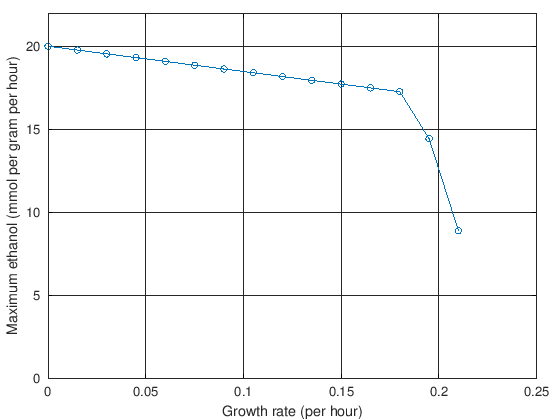

In [4]:
growth = linspace(0, 0.21, 15);                 % from no growth up to the maximum without oxygen
ethanol = zeros(size(growth));
for i = 1:numel(growth)
  m = changeRxnBounds(model, 'BIOMASS_Ecoli_core_w_GAM', growth(i), 'l');   % grow at least this fast
  m = changeObjective(m, 'EX_etoh_e');
  s = optimizeCbModel(m, 'max');
  ethanol(i) = s.f;
end
plot(growth, ethanol, 'o-', 'linewidth', 2)
xlabel('Growth rate (per hour)')
ylabel('Maximum ethanol (mmol per gram per hour)')
ylim([0 22])   % fixed axis, so every computer shows the same picture
grid on

**Question 2:** Describe the trade-off. If you ran a bioethanol company, which point on the line would you choose, and why?

✅ **Answer:** The faster the bacteria grow, the less ethanol they make. Up to a growth rate of about 0.18 per hour this costs only a little ethanol (20 → 17); after that, ethanol drops steeply to about 9 at maximum growth. Many would choose the "corner" at about 0.18: the bacteria still grow well and make almost as much ethanol as possible. There is no single right answer, though. A common strategy is to first let the bacteria grow fast (to get many workers), then switch them to production. Researchers also look for gene knockouts that force the cell to make ethanol *while* it grows.

## Your own product

**Succinate** (`EX_succ_e`) is used to make plastics and medicines. How much succinate can *E. coli* make at most from 10 glucose, without oxygen and with oxygen? Replace the `___`.

In [5]:
m = changeObjective(setMedium(model, 10, 0), 'EX_succ_e');
s = optimizeCbModel(m, 'max');
fprintf('%.1f\n', s.f)
m = changeObjective(setMedium(model, 10, 1000), 'EX_succ_e');
s = optimizeCbModel(m, 'max');
fprintf('%.1f\n', s.f)

Food: glucose uptake up to 10, oxygen uptake up to 0 (mmol per gram per hour).


13.9


Food: glucose uptake up to 10, oxygen uptake up to 1000 (mmol per gram per hour).


16.4


✅ **Answer:** About **13.9** without oxygen and **16.4** with oxygen. Unlike ethanol, here oxygen helps: making succinate needs extra energy and carbon dioxide, which the cell gets more easily by breathing.

**Congratulations!** 🎉 You've used the same methods that researchers use to study bacteria, find targets for new antibiotics and design bacterial factories. That's bioinformatics!

<small>Model: *E. coli* core model from BiGG Models (Orth et al. 2010; King et al. 2016). Software: COBRA Toolbox (Heirendt et al. 2019) in GNU Octave. Full sources at the end of `01_tutorial_fba.ipynb`.</small>